# Evaluation and Tuning

`05_modeling` left three models tied around 0.765 AUC on default settings. This notebook runs a
randomized search over each one and keeps a log of every trial, so the comparison is between tuned
models rather than whichever defaults happened to suit.

Models: logistic regression, random forest, extra trees, hist gradient boosting, LightGBM,
XGBoost, CatBoost.

`X_test` is used once, at the very end.

In [1]:
import sys, time, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

from sklearn.ensemble import (
    ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay, accuracy_score, brier_score_loss, classification_report,
    confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from utils.get_google_drive_data import load_csv_from_drive
from utils.google_drive_client import get_drive_client
from utils.utils import get_data_split
from utils.preprocessing import drop_leaks, feature_names, make_pipeline

pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42

In [2]:
# the boosting libraries are optional, skip any that are not installed
EXTRA = {}
try:
    from lightgbm import LGBMClassifier
    EXTRA["lightgbm"] = True
except ImportError:
    print("lightgbm not installed, skipping")
try:
    from xgboost import XGBClassifier
    EXTRA["xgboost"] = True
except ImportError:
    print("xgboost not installed, skipping")
try:
    from catboost import CatBoostClassifier
    EXTRA["catboost"] = True
except ImportError:
    print("catboost not installed, skipping")
print("available:", list(EXTRA))

available: ['lightgbm', 'xgboost', 'catboost']


In [3]:
service = get_drive_client()
df = load_csv_from_drive(service)

X_train, X_test, y_train, y_test = get_data_split(df)
X_train = drop_leaks(X_train)
X_test = drop_leaks(X_test)

print(f"train {X_train.shape}   test {X_test.shape}   base rate {y_train.mean():.3f}")

Please visit this URL to authorize this application: https://accounts.google.com/o/oauth2/auth?response_type=code&client_id=925533635529-41r57t84lmcbp8assc8mnk1kodvq0jri.apps.googleusercontent.com&redirect_uri=http%3A%2F%2Flocalhost%3A63436%2F&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive.readonly&state=qC8iXzgazh7P4ydK4O9TCCIRiV5H9L&access_type=offline
Found file: DSI_kickstarterscrape_dataset.csv
Download progress: 100%
train (29375, 11)   test (12590, 11)   base rate 0.547


## Search spaces

One entry per model: the estimator and the distributions to sample from. Parameters are prefixed
`model__` because they sit inside the pipeline.

In [4]:
class PyScalar:
    """Makes a scipy distribution yield plain python numbers.

    CatBoost will not clone an estimator whose params are numpy scalars,
    which is what scipy hands back by default.
    """

    def __init__(self, dist, cast=float):
        self.dist = dist
        self.cast = cast

    def rvs(self, *args, **kwargs):
        return self.cast(self.dist.rvs(*args, **kwargs))


SEARCHES = {
    "logistic": (
        LogisticRegression(max_iter=4000, solver="liblinear"),
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__penalty": ["l1", "l2"],
        },
    ),
    "random forest": (
        RandomForestClassifier(n_jobs=-1, random_state=SEED),
        {
            "model__n_estimators": randint(200, 800),
            "model__max_depth": [None, 8, 12, 20],
            "model__min_samples_leaf": randint(1, 30),
            "model__max_features": ["sqrt", "log2", 0.4, 0.7],
        },
    ),
    "extra trees": (
        ExtraTreesClassifier(n_jobs=-1, random_state=SEED),
        {
            "model__n_estimators": randint(200, 800),
            "model__max_depth": [None, 12, 20],
            "model__min_samples_leaf": randint(1, 30),
            "model__max_features": ["sqrt", "log2", 0.4],
        },
    ),
    "hist gradient boosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {
            "model__max_iter": randint(200, 800),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__max_leaf_nodes": randint(15, 64),
            "model__min_samples_leaf": randint(10, 60),
            "model__l2_regularization": loguniform(1e-3, 10),
        },
    ),
}

if EXTRA.get("lightgbm"):
    SEARCHES["lightgbm"] = (
        LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1),
        {
            "model__n_estimators": randint(200, 900),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__num_leaves": randint(15, 80),
            "model__min_child_samples": randint(10, 80),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.6, 0.4),
            "model__reg_lambda": loguniform(1e-3, 10),
        },
    )

if EXTRA.get("xgboost"):
    SEARCHES["xgboost"] = (
        XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss",
                      tree_method="hist"),
        {
            "model__n_estimators": randint(200, 900),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__max_depth": randint(3, 10),
            "model__min_child_weight": randint(1, 20),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.6, 0.4),
            "model__reg_lambda": loguniform(1e-3, 10),
        },
    )

if EXTRA.get("catboost"):
    SEARCHES["catboost"] = (
        CatBoostClassifier(random_seed=SEED, verbose=0, allow_writing_files=False),
        {
            "model__iterations": PyScalar(randint(200, 900), int),
            "model__learning_rate": PyScalar(loguniform(0.01, 0.3)),
            "model__depth": PyScalar(randint(4, 10), int),
            "model__l2_leaf_reg": PyScalar(loguniform(1, 30)),
        },
    )

print(f"{len(SEARCHES)} models to search")

7 models to search


## Running the search
samples per model, 5 fold CV, scored on ROC AUC. 

In [5]:
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
N_ITER = 25

log_rows = []
best = {}

for name, (estimator, space) in SEARCHES.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        make_pipeline(estimator),
        param_distributions=space,
        n_iter=N_ITER,
        scoring="roc_auc",
        cv=CV,
        n_jobs=-1,
        random_state=SEED,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    best[name] = search

    res = pd.DataFrame(search.cv_results_)
    for _, r in res.iterrows():
        log_rows.append({
            "model": name,
            "trial": int(r["rank_test_score"]),
            "cv_auc": r["mean_test_score"],
            "cv_std": r["std_test_score"],
            "train_auc": r["mean_train_score"],
            "gap": r["mean_train_score"] - r["mean_test_score"],
            "fit_sec": r["mean_fit_time"],
            "params": {k.replace("model__", ""): v for k, v in r["params"].items()},
        })
    print(f"{name:24s} best {search.best_score_:.4f}   {time.time()-t0:.0f}s")

experiment_log = pd.DataFrame(log_rows).sort_values("cv_auc", ascending=False).reset_index(drop=True)
print(f"\n{len(experiment_log)} trials logged")

logistic                 best 0.7648   65s
random forest            best 0.7664   298s
extra trees              best 0.7645   124s
hist gradient boosting   best 0.7691   65s
lightgbm                 best 0.7705   837s
xgboost                  best 0.7716   73s
catboost                 best 0.7724   353s

175 trials logged


## Experiment log

Every trial, best first.

In [6]:
experiment_log.head(20).round(4)

,model,trial,cv_auc,cv_std,train_auc,gap,fit_sec,params
0,catboost,1,0.7724,0.0060,0.8316,0.0592,11.3797,"{'depth': 5, 'iterations': 666, 'l2_leaf_reg':..."
1,catboost,2,0.7719,0.0059,0.7997,0.0278,11.4098,"{'depth': 4, 'iterations': 761, 'l2_leaf_reg':..."
2,catboost,3,0.7718,0.0059,0.8091,0.0373,5.6596,"{'depth': 4, 'iterations': 330, 'l2_leaf_reg':..."
3,catboost,4,0.7718,0.0061,0.8882,0.1165,84.2157,"{'depth': 9, 'iterations': 765, 'l2_leaf_reg':..."
4,catboost,5,0.7716,0.0062,0.8189,0.0473,27.1616,"{'depth': 7, 'iterations': 708, 'l2_leaf_reg':..."
5,xgboost,1,0.7716,0.0059,0.8104,0.0388,5.4469,"{'colsample_bytree': 0.7159005811655073, 'lear..."
6,catboost,6,0.7716,0.0066,0.8304,0.0588,45.9417,"{'depth': 8, 'iterations': 543, 'l2_leaf_reg':..."
7,catboost,7,0.7713,0.0056,0.7976,0.0263,86.6891,"{'depth': 4, 'iterations': 578, 'l2_leaf_reg':..."
8,catboost,8,0.7712,0.0059,0.8724,0.1012,73.9029,"{'depth': 9, 'iterations': 470, 'l2_leaf_reg':..."
9,xgboost,2,0.7712,0.0056,0.8469,0.0757,5.7879,"{'colsample_bytree': 0.7669644012595116, 'lear..."


In [7]:
summary = (experiment_log.groupby("model")
           .agg(best_auc=("cv_auc", "max"),
                worst_auc=("cv_auc", "min"),
                median_auc=("cv_auc", "median"),
                mean_gap=("gap", "mean"),
                median_fit_sec=("fit_sec", "median"),
                trials=("cv_auc", "size"))
           .sort_values("best_auc", ascending=False))
summary["spread"] = summary["best_auc"] - summary["worst_auc"]
summary.round(4)

,best_auc,worst_auc,median_auc,mean_gap,median_fit_sec,trials,spread
model,,,,,,,
catboost,0.7724,0.7414,0.7700,0.0886,31.8095,25,0.0310
xgboost,0.7716,0.7300,0.7595,0.1546,5.4955,25,0.0416
lightgbm,0.7705,0.7380,0.7533,0.1970,104.4498,25,0.0325
hist gradient boosting,0.7691,0.7570,0.7674,0.0657,4.2668,25,0.0121
random forest,0.7664,0.7593,0.7651,0.0960,25.4718,25,0.0071
logistic,0.7648,0.7343,0.7645,0.0039,4.1915,25,0.0305
extra trees,0.7645,0.7521,0.7583,0.0915,8.8424,25,0.0124


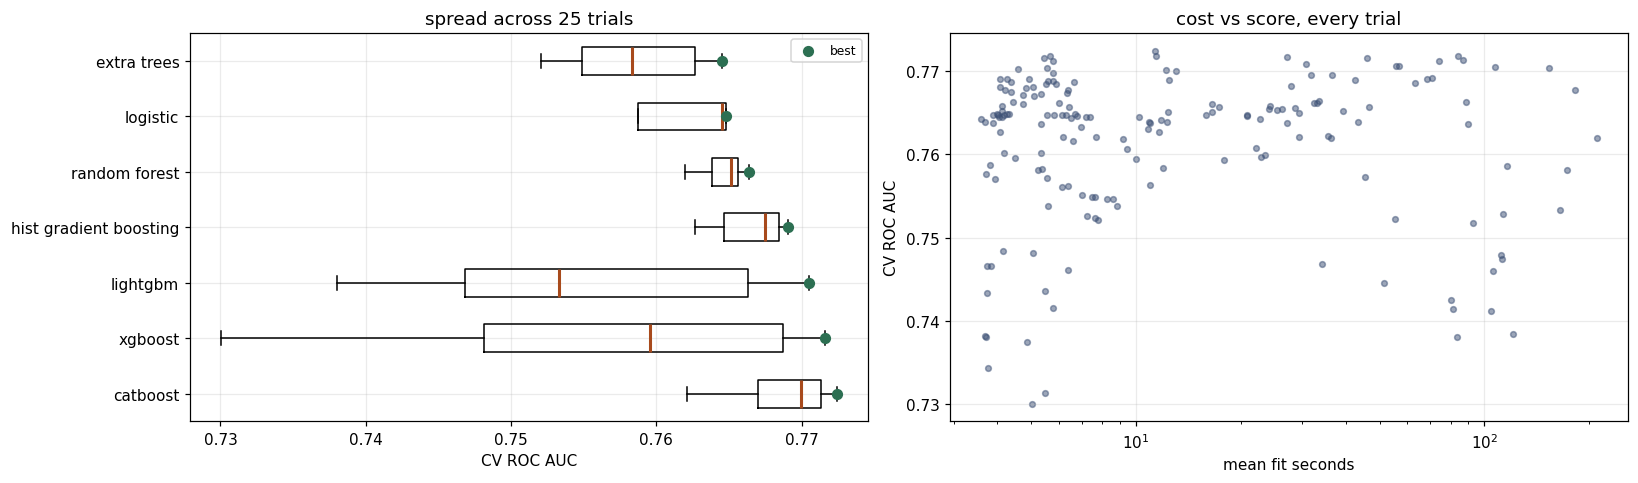

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

order = summary.index.tolist()
ax = axes[0]
ax.boxplot([experiment_log.loc[experiment_log["model"] == m, "cv_auc"] for m in order],
           tick_labels=order, orientation="horizontal", showfliers=False,
           medianprops=dict(color="#a84a1c", lw=2))
for i, m in enumerate(order):
    ax.scatter(summary.loc[m, "best_auc"], i + 1, color="#2c6f52", zorder=3, s=40, label="best" if i == 0 else "")
ax.set_xlabel("CV ROC AUC"); ax.set_title(f"spread across {N_ITER} trials"); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(experiment_log["fit_sec"], experiment_log["cv_auc"], s=14, alpha=0.5, color="#3b4f74")
ax.set_xscale("log"); ax.set_xlabel("mean fit seconds"); ax.set_ylabel("CV ROC AUC")
ax.set_title("cost vs score, every trial")
plt.tight_layout()

In [9]:
# the winning settings 
pd.DataFrame([
    {"model": m, "cv_auc": s.best_score_, **{k.replace("model__", ""): v for k, v in s.best_params_.items()}}
    for m, s in best.items()
]).set_index("model").sort_values("cv_auc", ascending=False).round(4)

,cv_auc,C,penalty,max_depth,max_features,min_samples_leaf,n_estimators,l2_regularization,learning_rate,max_iter,max_leaf_nodes,colsample_bytree,min_child_samples,num_leaves,reg_lambda,subsample,min_child_weight,depth,iterations,l2_leaf_reg
model,,,,,,,,,,,,,,,,,,,,
catboost,0.7724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,666.0,1.405
xgboost,0.7716,NaN,NaN,4.0,NaN,NaN,756.0,NaN,0.0173,NaN,NaN,0.7159,NaN,NaN,0.0152,0.6422,10.0,NaN,NaN,NaN
lightgbm,0.7705,NaN,NaN,NaN,NaN,NaN,846.0,NaN,0.0117,NaN,NaN,0.8370,60.0,35.0,0.0634,0.6053,NaN,NaN,NaN,NaN
hist gradient boosting,0.7691,NaN,NaN,NaN,NaN,29.0,NaN,1.7123,0.0282,764.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random forest,0.7664,NaN,NaN,20.0,0.4,12.0,708.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
logistic,0.7648,14.5282,l2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
extra trees,0.7645,NaN,NaN,20.0,0.4,8.0,661.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Tuned models on the top features

The search above used all 35 features, since the best settings for 35 columns are not the best for
12 and pruning before tuning locks in a choice made with untuned models. Now that each model has
its settings, check what the subset costs.

Importances come from the tuned tree models rather than the defaults used in `05_modeling`.

In [10]:
from sklearn.model_selection import cross_validate

tree_like = [m for m in ["catboost", "lightgbm", "xgboost", "random forest",
                         "extra trees", "hist gradient boosting"] if m in best]
ranks = []
for m in tree_like:
    est = best[m].best_estimator_
    fi = getattr(est.named_steps["model"], "feature_importances_", None)
    if fi is None:
        continue
    names = feature_names(est)
    ranks.append(pd.Series(fi, index=names).rank(ascending=False).rename(m))

rank_df = pd.concat(ranks, axis=1)
rank_df["mean_rank"] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values("mean_rank")

TOP_K = 12
top_features = rank_df.head(TOP_K).index.tolist()
print(f"ranking averaged over {len(ranks)} tuned models")
print(f"\ntop {TOP_K}:")
for f in top_features:
    print("  ", f)
rank_df.head(20).round(1)

ranking averaged over 5 tuned models

top 12:
   goal_per_tier
   te_subcategory
   te_state
   backers_needed
   duration
   n_tiers
   geo_step
   te_category
   goal_vs_subcat
   log_goal
   log_median_tier
   goal_per_day


,catboost,lightgbm,xgboost,random forest,extra trees,mean_rank
goal_per_tier,1.0,5.0,1.0,1.0,1.0,1.8
te_subcategory,2.0,2.0,3.0,3.0,2.0,2.4
te_state,3.0,1.0,6.0,4.0,5.0,3.8
backers_needed,6.0,6.0,2.0,2.0,3.0,3.8
duration,4.0,3.0,8.0,6.0,10.0,6.2
n_tiers,8.0,12.0,4.0,10.0,7.0,8.2
geo_step,5.0,4.0,7.0,5.0,22.0,8.6
te_category,10.0,13.0,14.0,7.0,4.0,9.6
goal_vs_subcat,7.0,7.0,19.0,9.0,9.0,10.2
log_goal,18.0,22.0,5.0,11.0,6.0,12.4


In [11]:
# refit each model's tuned settings on the subset, no new search
subset_rows = []
for name, search in best.items():
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    estimator = SEARCHES[name][0].__class__(**{**SEARCHES[name][0].get_params(), **params})
    cvres = cross_validate(make_pipeline(estimator, keep=top_features),
                           X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=-1)
    subset_rows.append({
        "model": name,
        "cv_auc_all": search.best_score_,
        f"cv_auc_top{TOP_K}": cvres["test_score"].mean(),
        "cv_std": cvres["test_score"].std(),
        "fit_sec": cvres["fit_time"].mean(),
    })

subset = pd.DataFrame(subset_rows).set_index("model")
subset["delta"] = subset[f"cv_auc_top{TOP_K}"] - subset["cv_auc_all"]
subset.sort_values(f"cv_auc_top{TOP_K}", ascending=False).round(4)

,cv_auc_all,cv_auc_top12,cv_std,fit_sec,delta
model,,,,,
catboost,0.7724,0.7669,0.0063,35.6363,-0.0055
xgboost,0.7716,0.7664,0.0059,17.5926,-0.0052
lightgbm,0.7705,0.7653,0.0067,66.6182,-0.0053
hist gradient boosting,0.7691,0.7644,0.0057,17.9600,-0.0047
random forest,0.7664,0.7629,0.0060,11.3760,-0.0035
extra trees,0.7645,0.7611,0.0052,36.5166,-0.0034
logistic,0.7648,0.7534,0.0048,3.0243,-0.0114


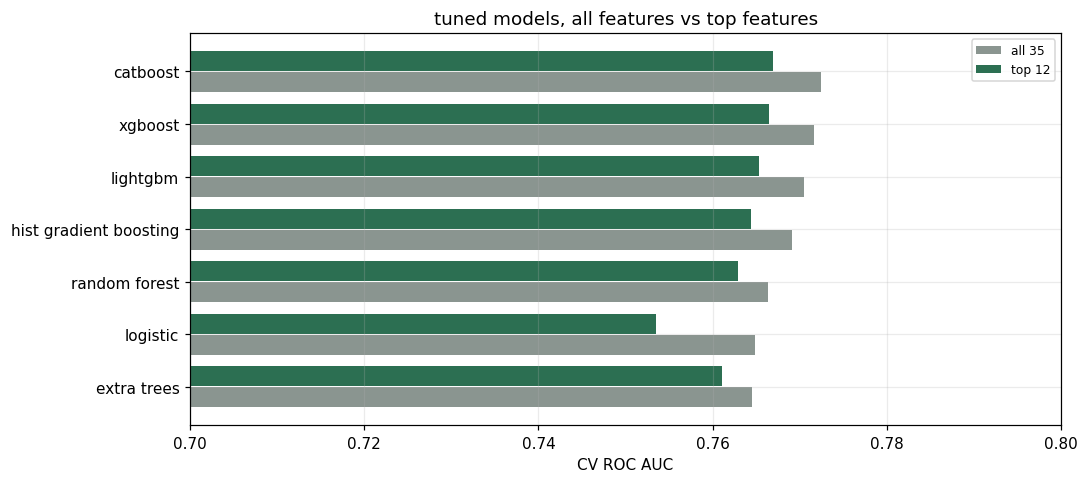

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
d = subset.sort_values("cv_auc_all")
y_pos = np.arange(len(d))
ax.barh(y_pos - 0.2, d["cv_auc_all"], height=0.38, color="#8a9590", label="all 35")
ax.barh(y_pos + 0.2, d[f"cv_auc_top{TOP_K}"], height=0.38, color="#2c6f52", label=f"top {TOP_K}")
ax.set_yticks(y_pos); ax.set_yticklabels(d.index)
ax.set_xlim(0.70, 0.80); ax.set_xlabel("CV ROC AUC"); ax.legend(fontsize=8)
ax.set_title("tuned models, all features vs top features")
plt.tight_layout()

A small negative `delta` means the subset is nearly free and worth taking if the model has to be
explained. A large one means those columns were carrying real signal.

## Final evaluation


In [13]:
winner_name = summary.index[0]
winner = best[winner_name].best_estimator_
print(f"winner: {winner_name}  (CV AUC {summary.loc[winner_name, 'best_auc']:.4f})")

proba = winner.predict_proba(X_test)[:, 1]
pred = proba >= 0.5

print(f"\ntest AUC      {roc_auc_score(y_test, proba):.4f}")
print(f"test accuracy {accuracy_score(y_test, pred):.4f}")
print(f"test F1       {f1_score(y_test, pred):.4f}")
print(f"test Brier    {brier_score_loss(y_test, proba):.4f}")
print(f"\nmajority class baseline: {max(y_test.mean(), 1 - y_test.mean()):.4f}")
print("\n", classification_report(y_test, pred, target_names=["failed", "funded"]))

winner: catboost  (CV AUC 0.7724)

test AUC      0.7722
test accuracy 0.7101
test F1       0.7513
test Brier    0.1908

majority class baseline: 0.5473

               precision    recall  f1-score   support

      failed       0.71      0.60      0.65      5699
      funded       0.71      0.80      0.75      6891

    accuracy                           0.71     12590
   macro avg       0.71      0.70      0.70     12590
weighted avg       0.71      0.71      0.71     12590



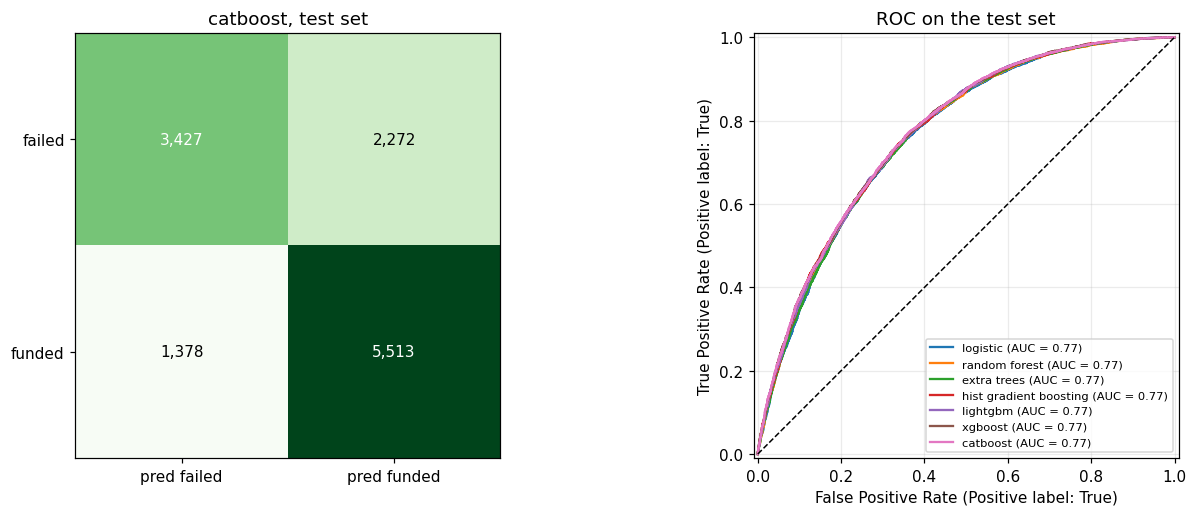

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

cm = confusion_matrix(y_test, pred)
im = axes[0].imshow(cm, cmap="Greens")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["pred failed", "pred funded"])
axes[0].set_yticks([0, 1], ["failed", "funded"])
axes[0].set_title(f"{winner_name}, test set"); axes[0].grid(False)

for name, s in best.items():
    RocCurveDisplay.from_estimator(s.best_estimator_, X_test, y_test, ax=axes[1], name=name, lw=1.5)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC on the test set"); axes[1].legend(fontsize=7.5, loc="lower right")
plt.tight_layout()

## Tune Threshold



tuned threshold 0.540
test accuracy at 0.5 0.7101
test accuracy at 0.540 0.7068


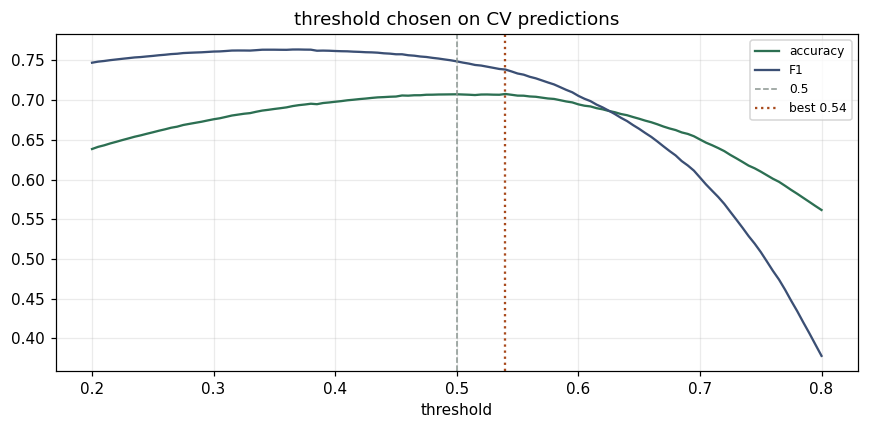

In [15]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(winner, X_train, y_train, cv=CV, method="predict_proba")[:, 1]
grid = np.linspace(0.2, 0.8, 121)
scores = pd.DataFrame({
    "threshold": grid,
    "accuracy": [accuracy_score(y_train, oof >= t) for t in grid],
    "f1": [f1_score(y_train, oof >= t) for t in grid],
})
best_t = scores.loc[scores["accuracy"].idxmax(), "threshold"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(scores["threshold"], scores["accuracy"], label="accuracy", color="#2c6f52")
ax.plot(scores["threshold"], scores["f1"], label="F1", color="#3b4f74")
ax.axvline(0.5, color="#8a9590", ls="--", lw=1, label="0.5")
ax.axvline(best_t, color="#a84a1c", ls=":", lw=1.5, label=f"best {best_t:.2f}")
ax.set_xlabel("threshold"); ax.legend(fontsize=8); ax.set_title("threshold chosen on CV predictions")
plt.tight_layout()

print(f"tuned threshold {best_t:.3f}")
print(f"test accuracy at 0.5 {accuracy_score(y_test, proba >= 0.5):.4f}")
print(f"test accuracy at {best_t:.3f} {accuracy_score(y_test, proba >= best_t):.4f}")

In [16]:
top = summary.index[0]
runner = summary.index[1]
test_auc = roc_auc_score(y_test, proba)

print(f"winner{top}")
print(f"CV AUC {summary.loc[top, 'best_auc']:.4f}")
print(f"test AUC {test_auc:.4f}   ({test_auc - summary.loc[top, 'best_auc']:+.4f} vs CV)")
print(f"next best {runner} at {summary.loc[runner, 'best_auc']:.4f} "
      f"({summary.loc[top, 'best_auc'] - summary.loc[runner, 'best_auc']:+.4f})")
print(f"tuning gain {summary.loc[top, 'best_auc'] - summary.loc[top, 'median_auc']:+.4f} "
      f"over its own median trial")
print(f"\nmost tuning sensitive: {summary['spread'].idxmax()} (spread {summary['spread'].max():.4f})")
print(f"least sensitive: {summary['spread'].idxmin()} (spread {summary['spread'].min():.4f})")
print(f"most overfit sampling: {summary['mean_gap'].idxmax()} (train minus CV {summary['mean_gap'].max():.3f})")

winnercatboost
CV AUC 0.7724
test AUC 0.7722   (-0.0003 vs CV)
next best xgboost at 0.7716 (+0.0008)
tuning gain +0.0025 over its own median trial

most tuning sensitive: xgboost (spread 0.0416)
least sensitive: random forest (spread 0.0071)
most overfit sampling: lightgbm (train minus CV 0.197)
